#

In [ ]:
---
execute:
  eval: false
  echo: true
  warning: false
format:
  html:
    code-fold: false
---

Importing the packages.

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import MNIST
import numpy as np
import matplotlib.pyplot as plt

from diffusers import UNet2DModel, DDPMScheduler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Setting the variance parameters.

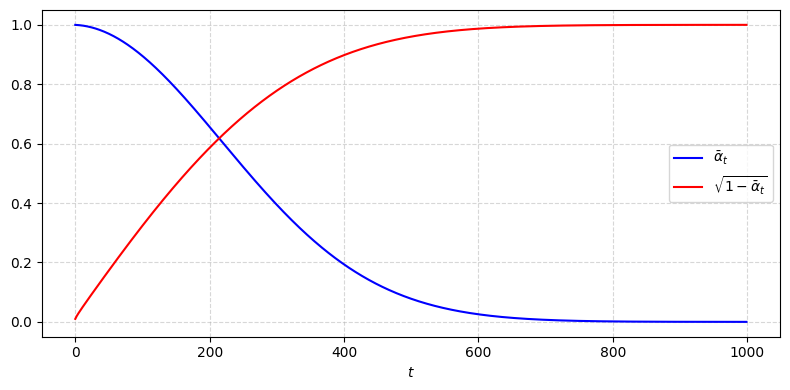

In [4]:
T = 1000
beta_start = 1e-4
beta_end = 0.02

betas = torch.linspace(beta_start, beta_end, T)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)

plt.figure(figsize=(8, 4))
plt.plot(alphas_cumprod.numpy(), label=r"$\bar{\alpha}_t$", color="blue")
plt.plot((1 - alphas_cumprod).sqrt().numpy(), label=r"$\sqrt{1 - \bar{\alpha}_t}$", color="red")
plt.xlabel(r"$t$")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Downloading MNIST and showing the corruption of the data.

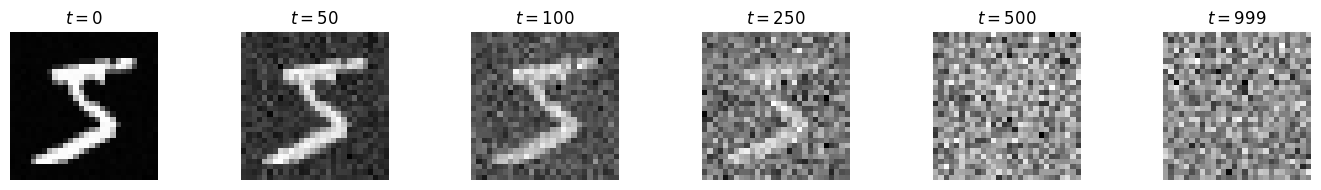

In [7]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
dataset = MNIST(root="./data", train=True, download=True, transform=transform)
x0, _ = dataset[0]
x0 = x0.unsqueeze(0)

def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    alpha_bar_t = alphas_cumprod[t].view(-1, 1, 1, 1).to(x0.device)
    xt = torch.sqrt(alpha_bar_t) * x0 + torch.sqrt(1.0 - alpha_bar_t) * noise
    return xt, noise

timesteps_to_show = [0, 50, 100, 250, 500, 999]
fig, axes = plt.subplots(1, len(timesteps_to_show), figsize=(14, 2))

for i, t in enumerate(timesteps_to_show):
    xt, _ = q_sample(x0, torch.tensor([t]))
    img = (xt.squeeze().numpy() + 1) / 2.0
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(r"$t=$" + f"{t}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Setting the neural network and the scheduler.

In [14]:
model = UNet2DModel(
    sample_size=28,
    in_channels=1,
    out_channels=1,
    layers_per_block=2,
    block_out_channels=(32, 64),
    down_block_types=("DownBlock2D", "DownBlock2D"),
    up_block_types=("UpBlock2D", "UpBlock2D"),
).to(device)

scheduler = DDPMScheduler(
    num_train_timesteps=T,
    beta_start=beta_start,
    beta_end=beta_end,
    beta_schedule="linear"
)

Training the model.

In [15]:
train_loader = DataLoader(dataset, batch_size=512, shuffle=True, drop_last=True)
optimizer = optim.AdamW(model.parameters(), lr=2e-4)

epochs = 5
model.train()

for epoch in range(1, epochs + 1):
    total_loss = 0.0
    for x0, _ in train_loader:
        x0 = x0.to(device)
        batch_size = x0.size(0)

        t = torch.randint(0, T, (batch_size,), device=device).long()
        noise = torch.randn_like(x0)
        xt = scheduler.add_noise(x0, noise, t)
        noise_pred = model(xt, t).sample
        loss = F.mse_loss(noise_pred, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch:02d}/{epochs:02d}] | Loss: {avg_loss:.4f}")

Epoch [01/05] | Loss: 0.1553
Epoch [02/05] | Loss: 0.0554
Epoch [03/05] | Loss: 0.0440
Epoch [04/05] | Loss: 0.0393
Epoch [05/05] | Loss: 0.0361

Sampling using Ancestral Sampling.

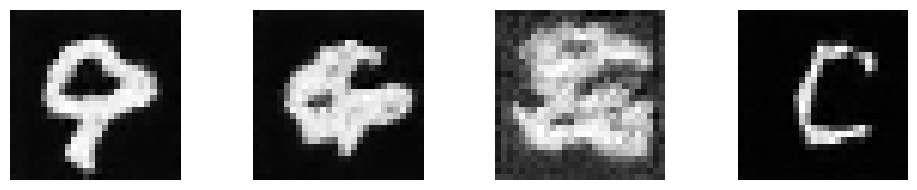

In [21]:
@torch.no_grad()
def ancestral_sampling(model, scheduler, num_samples=4):
    model.eval()
    scheduler.set_timesteps(T)

    x = torch.randn((num_samples, 1, 28, 28), device=device)

    for t in scheduler.timesteps:
        noise_pred = model(x, t).sample
        x = scheduler.step(noise_pred, t, x).prev_sample

    return x.clamp(-1.0, 1.0)

samples = ancestral_sampling(model, scheduler, num_samples=4)

samples = (samples.cpu() + 1.0) / 2.0
samples = samples.permute(0, 2, 3, 1).numpy()

fig, axes = plt.subplots(1, 4, figsize=(10, 2))
for i in range(4):
    axes[i].imshow(samples[i, :, :, 0], cmap="gray")
    axes[i].axis("off")
plt.tight_layout()
plt.show()